# QAOA on a REAL IBM Quantum Processor

requirements: minimize $-x_0x_1x_2$; compare **H → CX → RZ → CX → RX** (Pauli decomposition) against the **Toffoli / CCX** approach.

Execution: optimize once on ideal simulator, validate equivalence, run both circuits on a real IBM QPU, and compare measured success rates and native gate counts.


## 1. Connect to IBM Quantum Platform


In [ ]:

from qiskit_ibm_runtime import QiskitRuntimeService

# Replace xyz with your NEW API key
api_key = "xyz"

# Replace the example with your actual CRN
crn = "xyz"

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=crn
)

print("Connected to IBM Quantum!")

for backend in service.backends(
    simulator=False,
    operational=True
):
    print(backend.name)


qiskit_runtime_service._discover_account:WARNING:2026-11-23 15:40:37,576: Loading account with the given token. A saved account will not be used.


Connected to IBM Quantum!
ibm_fez
ibm_kingston
ibm_marrakesh


In [38]:

# Display all available IBM quantum processors
for qpu in service.backends(
    simulator=False,
    operational=True
):
    print(qpu.name)

# Explicitly select IBM Marrakesh
backend = service.backend("ibm_marrakesh")

print("Selected backend:", backend.name)
print("Number of qubits:", backend.num_qubits)


ibm_fez
ibm_kingston
ibm_marrakesh
Selected backend: ibm_marrakesh
Number of qubits: 156


In [39]:
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

@dataclass(frozen=True)
class Settings:
    shots: int = 4096
    seed: int = 42
    qaoa_layers: int = 1  # The whiteboard experiment uses p = 1

cfg = Settings()
assert cfg.qaoa_layers == 1


## 2. Objective and expected solution

$\displaystyle f(x_0,x_1,x_2)=-x_0x_1x_2$.

For QAOA, $H_C=-\lvert111\rangle\langle111\rvert$, so $U_C(\gamma)=e^{-i\gamma H_C}$ gives $\lvert111\rangle$ a phase $e^{+i\gamma}$ and leaves all other computational states unchanged. The mixer is $H_M=X_0+X_1+X_2$.

In [40]:
bitstrings = [f"{i:03b}" for i in range(8)]
objective_table = pd.DataFrame({
    "state": bitstrings,
    "f(x) = -x0*x1*x2": [-int(s[0]) * int(s[1]) * int(s[2]) for s in bitstrings],
})
display(objective_table)
assert objective_table.loc[objective_table["state"] == "111", "f(x) = -x0*x1*x2"].item() == -1


,state,f(x) = -x0*x1*x2
0,000,0
1,001,0
2,010,0
3,011,0
4,100,0
5,101,0
6,110,0
7,111,-1


## 3. Implementation A — H → CX → RZ → CX → RX

Using $x_j=(I-Z_j)/2$,

$\displaystyle H_C=\tfrac18(-I+Z_0+Z_1+Z_2-Z_0Z_1-Z_0Z_2-Z_1Z_2+Z_0Z_1Z_2).$

Each nonconstant Pauli-Z string is implemented by computing parity with CX gates, rotating with RZ, and reversing the CX gates. The identity contributes only a global phase and is omitted.

In [41]:
# (qubit indices, Pauli expansion coefficient)
Z_TERMS = (
    ((0,), 1/8), ((1,), 1/8), ((2,), 1/8),
    ((0, 1), -1/8), ((0, 2), -1/8), ((1, 2), -1/8),
    ((0, 1, 2), 1/8),
)

def parity_phase(circuit: QuantumCircuit, support: tuple[int, ...], angle: float) -> None:
    """Implement exp(-i * angle/2 * product(Z[q] for q in support))."""
    for control, target in zip(support[:-1], support[1:]):
        circuit.cx(control, target)
    circuit.rz(angle, support[-1])
    for control, target in reversed(list(zip(support[:-1], support[1:]))):
        circuit.cx(control, target)

def pauli_cost(circuit: QuantumCircuit, gamma: float) -> None:
    for support, weight in Z_TERMS:
        parity_phase(circuit, support, 2 * gamma * weight)


## 4. Implementation B — Toffoli / CCX method

One **ancilla** qubit, $q_3$, is initialized in $\lvert0\rangle$:

- CCX$(q_0,q_1\rightarrow q_3)$ computes $x_0x_1$.
- CP$(\gamma)$ between $q_3$ and $q_2$ adds the required phase **only** for **111**.
- A second CCX uncomputes the ancilla to $\lvert0\rangle$.

**Note:** A Toffoli gate on its own is not the QAOA cost unitary; the CP gate is essential.

In [42]:
def toffoli_cost(circuit: QuantumCircuit, gamma: float) -> None:
    ancilla = 3
    circuit.ccx(0, 1, ancilla)
    circuit.cp(gamma, ancilla, 2)
    circuit.ccx(0, 1, ancilla)


def qaoa_circuit(method: str, gamma: float, beta: float, *, measure: bool = False) -> QuantumCircuit:
    """Construct whiteboard QAOA p=1; only the three data qubits are measured."""
    if method not in ("pauli", "toffoli"):
        raise ValueError("method must be 'pauli' or 'toffoli'")
    num_qubits = 3 if method == "pauli" else 4
    circuit = QuantumCircuit(num_qubits, 3) if measure else QuantumCircuit(num_qubits)
    for qubit in range(3):
        circuit.h(qubit)  # H: equal superposition
    circuit.barrier()
    if method == "pauli":
        pauli_cost(circuit, gamma)
    else:
        toffoli_cost(circuit, gamma)
    circuit.barrier()
    for qubit in range(3):
        circuit.rx(2 * beta, qubit)  # RX mixer
    if measure:
        circuit.measure([0, 1, 2], [0, 1, 2])
    return circuit

sample_gamma, sample_beta = 1.0, 0.5
for method in ("pauli", "toffoli"):
    print(f"\n{method.upper()} circuit:")
    print(qaoa_circuit(method, sample_gamma, sample_beta).draw(output="text"))



PAULI circuit:
     ┌───┐ ░ ┌──────────┐                                                   »
q_0: ┤ H ├─░─┤ Rz(0.25) ├──■─────────────────■────■─────────────────■───────»
     ├───┤ ░ ├──────────┤┌─┴─┐┌───────────┐┌─┴─┐  │                 │       »
q_1: ┤ H ├─░─┤ Rz(0.25) ├┤ X ├┤ Rz(-0.25) ├┤ X ├──┼─────────────────┼────■──»
     ├───┤ ░ ├──────────┤└───┘└───────────┘└───┘┌─┴─┐┌───────────┐┌─┴─┐┌─┴─┐»
q_2: ┤ H ├─░─┤ Rz(0.25) ├───────────────────────┤ X ├┤ Rz(-0.25) ├┤ X ├┤ X ├»
     └───┘ ░ └──────────┘                       └───┘└───────────┘└───┘└───┘»
«                                                        ░ ┌───────┐
«q_0: ────────────────────■──────────────────────────■───░─┤ Rx(1) ├
«                       ┌─┴─┐                      ┌─┴─┐ ░ ├───────┤
«q_1: ───────────────■──┤ X ├──■────────────────■──┤ X ├─░─┤ Rx(1) ├
«     ┌───────────┐┌─┴─┐└───┘┌─┴─┐┌──────────┐┌─┴─┐└───┘ ░ ├───────┤
«q_2: ┤ Rz(-0.25) ├┤ X ├─────┤ X ├┤ Rz(0.25) ├┤ X ├──────░─┤ Rx(1) ├
«     └───────────┘└───┘

## 5. Optimize the same $(\gamma,\beta)$ for both methods

Optimization runs on **ideal statevectors**; it does not consume IBM QPU time. Because the two circuit methods represent the same QAOA unitary (up to global phase and an uncomputed ancilla), one optimized parameter pair is shared.

In [43]:
def data_probabilities(method: str, gamma: float, beta: float) -> np.ndarray:
    state = Statevector.from_instruction(qaoa_circuit(method, gamma, beta))
    return np.asarray(state.probabilities(qargs=[0, 1, 2]), dtype=float)


def success_probability(params: np.ndarray) -> float:
    gamma, beta = params
    return float(data_probabilities("pauli", gamma, beta)[7])

search = differential_evolution(
    lambda params: -success_probability(params),
    bounds=[(0, 2 * np.pi), (0, np.pi)],
    seed=cfg.seed,
    tol=1e-10,
    polish=True,
)
gamma_star, beta_star = map(float, search.x)
print(f"Optimized gamma = {gamma_star:.8f}")
print(f"Optimized beta  = {beta_star:.8f}")
print(f"Ideal P(111)   = {success_probability(search.x):.4%}")
print(f"Ideal <H_C>    = {-success_probability(search.x):.8f}")


Optimized gamma = 4.15708415
Optimized beta  = 0.50774513
Ideal P(111)   = 42.4474%
Ideal <H_C>    = -0.42447397


## 6. Validate the two implementations

The Pauli and Toffoli circuit outputs must produce the same **three-data-qubit** probability distribution in ideal simulation. This is an essential correctness check before comparing noisy hardware performance.

PASS: both methods agree across all 8 data bitstrings.
Ideal P(111): 0.424474


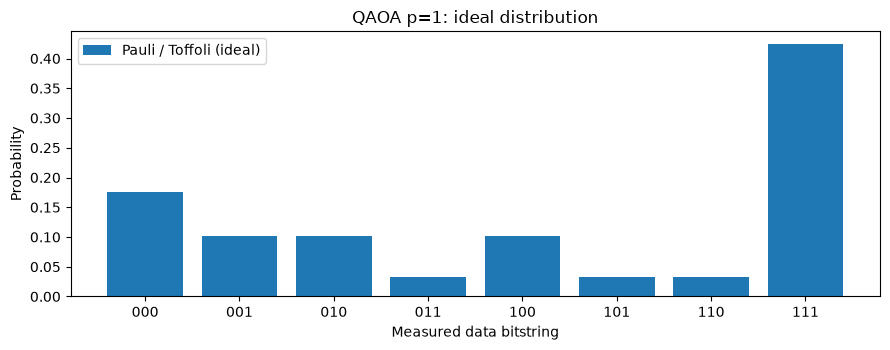

In [44]:
ideal_pauli = data_probabilities("pauli", gamma_star, beta_star)
ideal_toffoli = data_probabilities("toffoli", gamma_star, beta_star)
assert np.allclose(ideal_pauli, ideal_toffoli, atol=1e-10), "Cost-unitary mismatch"
assert np.isclose(ideal_pauli.sum(), 1.0)
print("PASS: both methods agree across all 8 data bitstrings.")
print("Ideal P(111):", round(float(ideal_pauli[7]), 6))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(bitstrings, ideal_pauli, label="Pauli / Toffoli (ideal)")
ax.set(xlabel="Measured data bitstring", ylabel="Probability", title="QAOA p=1: ideal distribution")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Gate counts and circuit depth before hardware compilation

These are **logical-level** counts. Native device gate counts depend on the backend coupling map, gate set, calibration and compiler version.

In [45]:
rows = []
for method in ("pauli", "toffoli"):
    circuit = qaoa_circuit(method, gamma_star, beta_star)
    operations = circuit.count_ops()
    rows.append({
        "method": method,
        "logical_qubits": circuit.num_qubits,
        "depth (logical)": circuit.depth(),
        "H": operations.get("h", 0),
        "CX": operations.get("cx", 0),
        "RZ": operations.get("rz", 0),
        "CCX": operations.get("ccx", 0),
        "CP": operations.get("cp", 0),
        "RX": operations.get("rx", 0),
    })
logical_resources = pd.DataFrame(rows)
display(logical_resources)


,method,logical_qubits,depth (logical),H,CX,RZ,CCX,CP,RX
0,pauli,3,17,3,10,7,0,0,3
1,toffoli,4,5,3,0,0,2,1,3


## 8. Select a real QPU and compile both circuits

We require at least 4 physical qubits; the Toffoli circuit uses an ancilla.

In [46]:

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Use the already selected IBM Quantum backend
print("Selected REAL QPU:", backend.name)
print("Available qubits:", backend.num_qubits)

# Generate hardware-aware transpilation pass manager
pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=2,
    seed_transpiler=cfg.seed
)

# Build both QAOA circuits
METHODS = ("pauli", "toffoli")

logical_circuits = [
    qaoa_circuit(
        method,
        gamma_star,
        beta_star,
        measure=True
    )
    for method in METHODS
]

# Transpile circuits for IBM hardware
isa_circuits = [
    pass_manager.run(circuit)
    for circuit in logical_circuits
]

# Display hardware circuit statistics
for method, qc in zip(METHODS, isa_circuits):
    print(f"\nMethod: {method.upper()}")
    print(f"Circuit depth: {qc.depth()}")
    print(f"Native operations: {dict(qc.count_ops())}")


Selected REAL QPU: ibm_marrakesh
Available qubits: 156

Method: PAULI
Circuit depth: 51
Native operations: {'rz': 32, 'sx': 30, 'cz': 13, 'measure': 3, 'barrier': 2}

Method: TOFFOLI
Circuit depth: 75
Native operations: {'sx': 46, 'rz': 44, 'cz': 21, 'measure': 3, 'barrier': 2, 'x': 2}


## 9. SUBMIT both circuits to the real QPU

**This cell sends a real hardware job.** Run it **once**. IBM may count this against your instance quota or billable usage. Save the printed job ID. Do not rerun merely to retrieve results.

In [47]:
from qiskit_ibm_runtime import SamplerV2

sampler = SamplerV2(mode=backend)
job = sampler.run(isa_circuits, shots=cfg.shots)
JOB_ID = job.job_id()
print("Hardware job submitted successfully")
print("Backend:", backend.name)
print("JOB_ID:", JOB_ID)
print("Save JOB_ID above to retrieve without submitting again.")

Hardware job submitted successfully
Backend: ibm_marrakesh
JOB_ID: dc1tvranj2vs73dfs4n0
Save JOB_ID above to retrieve without submitting again.


## 10. Retrieve QPU results (without resubmitting)

If the kernel restarted, reconnect using Section 8 and paste your existing job ID into `JOB_ID` below. This reads the existing job rather than submitting a new one.

In [48]:
# Uncomment and fill ONLY if resuming a previously submitted job:
# JOB_ID = "your-existing-ibm-job-id"

completed_job = service.job(JOB_ID)
print("Job status:", completed_job.status())
result = completed_job.result()  # Waits for an existing job to finish
real_counts = {
    method: result[index].data.c.get_counts()
    for index, method in enumerate(METHODS)
}
for method, counts in real_counts.items():
    total = sum(counts.values())
    print(f"{method}: {counts.get('111', 0)}/{total} = {counts.get('111', 0)/total:.4%} P(111)")

Job status: QUEUED
pauli: 1534/4096 = 37.4512% P(111)
toffoli: 1383/4096 = 33.7646% P(111)


## 11. Compare ideal and REAL QPU results

Because $f(111)=-1$ and all other states have cost zero, $\langle H_C\rangle=-P(111)$.

,Circuit,QPU,Shots,Ideal P(111),QPU P(111),QPU <H_C>,Native depth,Native two-qubit gates
0,pauli,ibm_marrakesh,4096,0.424474,0.374512,-0.374512,51,13
1,toffoli,ibm_marrakesh,4096,0.424474,0.337646,-0.337646,75,21


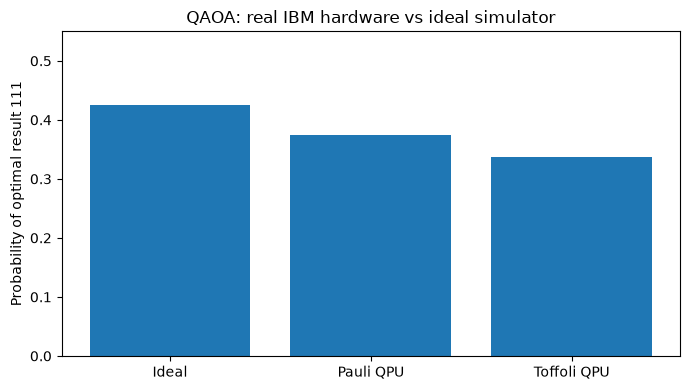

Saved: qaoa_ibm_qpu_comparison.csv


In [49]:
comparison = []
for method, native, raw in zip(METHODS, isa_circuits, (real_counts[m] for m in METHODS)):
    n = sum(raw.values())
    p111 = raw.get("111", 0)/n
    comparison.append({
        "Circuit": method,
        "QPU": backend.name,
        "Shots": n,
        "Ideal P(111)": ideal_pauli[7],
        "QPU P(111)": p111,
        "QPU <H_C>": -p111,
        "Native depth": native.depth(),
        "Native two-qubit gates": sum(v for k,v in native.count_ops().items() if k in {"cz","cx","ecr","rzz","iswap"}),
    })
comparison_df = pd.DataFrame(comparison)
display(comparison_df)
comparison_df.to_csv("qaoa_ibm_qpu_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(7,4))
ax.bar(["Ideal", "Pauli QPU", "Toffoli QPU"],
       [ideal_pauli[7], comparison_df.loc[0,"QPU P(111)"], comparison_df.loc[1,"QPU P(111)"]])
ax.set_ylabel("Probability of optimal result 111")
ax.set_ylim(0, max(0.55, float(comparison_df["QPU P(111)"].max())+0.05))
ax.set_title("QAOA: real IBM hardware vs ideal simulator")
plt.tight_layout()
plt.show()
print("Saved: qaoa_ibm_qpu_comparison.csv")